# E-commerce Sales Analysis

**Goal:** Analyze two years of online store data (2024-2025) to understand revenue, profit, customer value and returns.

**Tools:** Python, Pandas, Matplotlib, Google Colab

In [34]:
import pandas as pd

In [35]:
customers = pd.read_csv("customers.csv")
orders = pd.read_csv("orders.csv")
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv("products.csv")

print(customers.shape, orders.shape, order_items.shape, products.shape)

(3600, 4) (9245, 7) (15608, 5) (90, 5)


In [36]:
for name, df in [("customers", customers), ("orders", orders),
                 ("order_items", order_items), ("products", products)]:
    print("=====", name, df.shape)
    print(df.head())
    print(df.isna().sum())
    print("duplicates:", df.duplicated().sum())
    print()

===== customers (3600, 4)
   customer_id signup_date state acquisition_channel
0            1  2024-09-13    CO      organic_search
1            2  2025-10-21    IL         paid_search
2            3  2025-01-17    AZ            referral
3            4  2024-06-23    FL         paid_social
4            5  2025-04-08    IL         paid_social
customer_id            0
signup_date            0
state                  0
acquisition_channel    0
dtype: int64
duplicates: 0

===== orders (9245, 7)
   order_id  customer_id           order_date     status payment_method  \
0    100001         1530  2024-01-01 09:24:45  completed    credit_card   
1    100002         3531  2024-01-01 10:37:49  completed    credit_card   
2    100003          840  2024-01-01 10:59:09  completed    credit_card   
3    100004          725  2024-01-01 12:48:34  completed      apple_pay   
4    100005         3452  2024-01-01 17:44:03  completed      gift_card   

  discount_code  shipping_fee  
0           NaN       

In [37]:

# Clean the data


# 1. Remove duplicate orders
print("Orders before:", orders.shape[0])
orders = orders.drop_duplicates()
print("Orders after:", orders.shape[0])

# 2. Clean category names (Kitchen, kitchen, " Kitchen" -> Kitchen)
print("Categories before:", products["category"].nunique())
products["category"] = products["category"].str.strip().str.title()
print("Categories after:", products["category"].nunique())

# 3. Fill missing unit_price using the product's list_price
print("Missing prices before:", order_items["unit_price"].isna().sum())
order_items = order_items.merge(products[["product_id", "list_price"]],
                                on="product_id", how="left")
order_items["unit_price"] = order_items["unit_price"].fillna(order_items["list_price"])
order_items = order_items.drop(columns="list_price")
print("Missing prices after:", order_items["unit_price"].isna().sum())

# 4. Convert text dates to real dates
orders["order_date"] = pd.to_datetime(orders["order_date"])
customers["signup_date"] = pd.to_datetime(customers["signup_date"])

Orders before: 9245
Orders after: 9207
Categories before: 24
Categories after: 8
Missing prices before: 199
Missing prices after: 0


In [38]:

# Merge the four tables into one

df = (order_items
      .merge(orders, on="order_id", how="left")
      .merge(products, on="product_id", how="left")
      .merge(customers, on="customer_id", how="left"))

# Create the main money columns
df["revenue"] = df["quantity"] * df["unit_price"] - df["discount_amount"]
df["cost"] = df["quantity"] * df["unit_cost"]
df["profit"] = df["revenue"] - df["cost"]

# Time columns for trends
df["month"] = df["order_date"].dt.to_period("M")
df["year"] = df["order_date"].dt.year

print(df.shape)
df.head()

(15608, 23)


,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,...,list_price,unit_cost,signup_date,state,acquisition_channel,revenue,cost,profit,month,year
0,100001,1031,1,38.99,0.0,1530,2024-01-01 09:24:45,completed,credit_card,NaN,...,38.99,20.19,2023-12-30,AZ,organic_search,38.99,20.19,18.80,2024-01,2024
1,100002,1087,1,45.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,...,45.99,20.30,2023-11-19,VA,organic_search,45.99,20.30,25.69,2024-01,2024
2,100002,1072,1,141.99,0.0,3531,2024-01-01 10:37:49,completed,credit_card,NaN,...,141.99,62.78,2023-11-19,VA,organic_search,141.99,62.78,79.21,2024-01,2024
3,100003,1048,1,139.99,0.0,840,2024-01-01 10:59:09,completed,credit_card,NaN,...,139.99,71.41,2023-10-30,MN,organic_search,139.99,71.41,68.58,2024-01,2024
4,100004,1083,1,19.99,2.0,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,...,19.99,9.51,2023-08-20,MI,paid_search,17.99,9.51,8.48,2024-01,2024


In [39]:

# Keep only completed orders for revenue

completed = df[df["status"] == "completed"]

print("Total revenue:", round(completed["revenue"].sum()))
print("Total profit:", round(completed["profit"].sum()))
print("Completed orders:", completed["order_id"].nunique())
print("Avg order value:", round(completed.groupby("order_id")["revenue"].sum().mean(), 2))

Total revenue: 1881275
Total profit: 925249
Completed orders: 8456
Avg order value: 222.48


In [40]:
import matplotlib.pyplot as plt


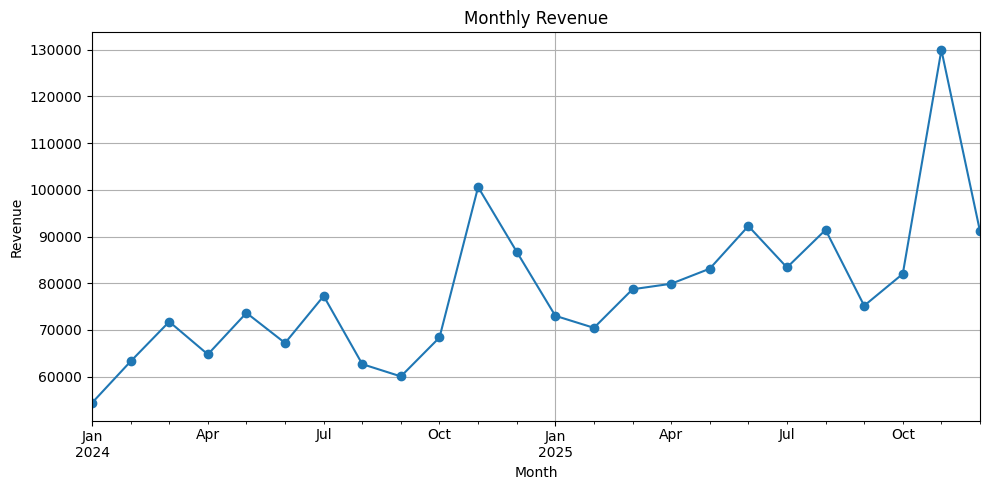

In [41]:
#  Monthly revenue trend

monthly = completed.groupby("month")["revenue"].sum()

monthly.plot(kind="line", marker="o", figsize=(10, 5), title="Monthly Revenue")
plt.ylabel("Revenue")
plt.xlabel("Month")
plt.grid(True)
plt.tight_layout()
plt.savefig("monthly_revenue.png")
plt.show()

**Insight:** Revenue grew about 21% from 2024 to 2025. November is the peak month in both years, so the business is seasonal around the holidays.

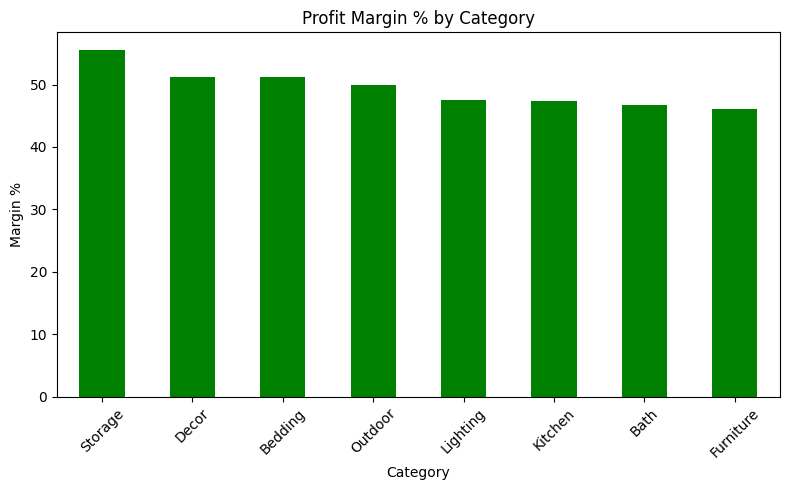

In [42]:
# Profit margin by category

cat["margin_%"].sort_values(ascending=False).plot(kind="bar", figsize=(8, 5),
                                                 title="Profit Margin % by Category",
                                                 color="green")
plt.ylabel("Margin %")
plt.xlabel("Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("margin_by_category.png")
plt.show()

**Insight:** Storage has the highest profit margin (55.6%), followed by Bedding and Decor (both about 51%). Furniture has the lowest margin (46.2%), even though it earns the most revenue. Margins across all categories stay between 46% and 56%, so no category is unprofitable, but Furniture earns the least profit per sale.

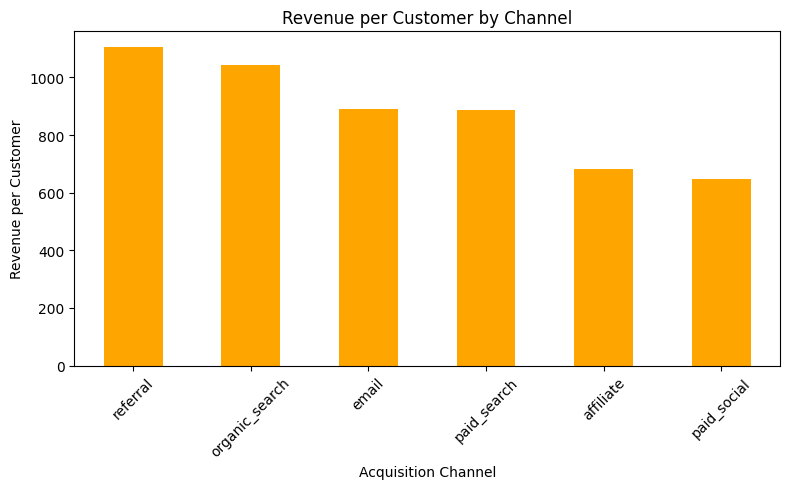

In [43]:
#Revenue per customer by acquisition channel


ch = completed.groupby("acquisition_channel").agg(revenue=("revenue", "sum"),
                                                  customers=("customer_id", "nunique"))
ch["revenue_per_customer"] = (ch["revenue"] / ch["customers"]).round(0)

ch["revenue_per_customer"].sort_values(ascending=False).plot(kind="bar", figsize=(8, 5),
                                                             title="Revenue per Customer by Channel",
                                                             color="orange")
plt.ylabel("Revenue per Customer")
plt.xlabel("Acquisition Channel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("revenue_by_channel.png")
plt.show()

**Insight:** Referral customers spend the most (about 1,105 per customer), followed by organic search (about 1,044). Email and paid search are in the middle (about 890 each). Affiliate (about 683) and paid social (about 649) bring the lowest-value customers, roughly 40% less than referral.

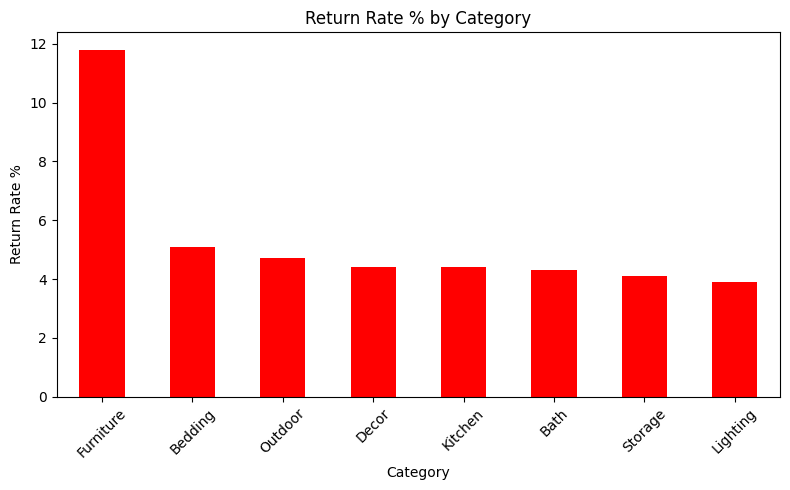

In [44]:
# Return rate by category


return_rate = df.groupby("category")["status"].apply(lambda s: (s == "returned").mean() * 100).round(1)

return_rate.sort_values(ascending=False).plot(kind="bar", figsize=(8, 5),
                                              title="Return Rate % by Category",
                                              color="red")
plt.ylabel("Return Rate %")
plt.xlabel("Category")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("return_rate_by_category.png")
plt.show()

**Insight:** Furniture has a return rate of about 11.8%, far above every other category (about 4-5%). Returns are a clear problem in the biggest revenue category.

## Conclusion

1. **Fix Furniture first.** It is the top revenue category, but it has the lowest margin (46.2%) and the highest return rate (11.8%). Investigate the causes of returns.
2. **Invest in referral and organic search.** These bring the highest-value customers (about 1,105 and 1,044 per customer).
3. **Review paid social and affiliate spending.** These customers spend about 40% less than referral customers.
4. **Prepare for November.** It is the peak month in both years, so plan stock and campaigns early.

In [46]:

# Save and download

df.to_csv("cleaned_ecommerce_data.csv", index=False)

from google.colab import files
files.download("cleaned_ecommerce_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>